# Notebook 02: Funnel Conversion, Econometric Drivers, Cohort Vintages & Scenarios
**Portfolio Project:** Lending Product Funnel & Approval Analysis  
**Institutional Framing:** Retail Lending Product Analyst at an Indian NBFC (e.g. Bajaj Finance)  
**Objective:** Calculate stage conversions with 95% Wilson Score CIs, estimate econometric approval drivers, evaluate cohort vintage maturation curves, construct the segment risk-return matrix, and simulate policy scenarios.


In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.stats import wilson_score_interval, two_proportion_z_test
from src.modeling import fit_approval_logistic_regression, load_model_sample
from src.scenario import run_all_scenarios

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

con = duckdb.connect()
print("Dependencies loaded successfully.")


Dependencies loaded successfully.


## 1. Funnel Stage Conversion Rates (Stages 1 -> 2 -> 3)
In public Lending Club records, "approved" reflects **funded/disbursed** loans because approved-but-not-taken offers are unrecorded.


In [2]:
df_funnel = pd.read_csv('data/marts/mart_funnel_summary.csv')
total_app = df_funnel.loc[df_funnel['stage_name'] == 'Stage 1: Applied', 'applicant_count'].values[0]
funded_app = df_funnel.loc[df_funnel['stage_name'] == 'Stage 2: Approved and Funded', 'applicant_count'].values[0]

df_funnel['stage_conversion_pct'] = np.where(
    df_funnel['stage_order'] <= 2,
    (df_funnel['applicant_count'] / total_app) * 100,
    (df_funnel['applicant_count'] / funded_app) * 100
)

df_funnel


,stage_name,stage_order,applicant_count,stage_conversion_pct
0,Stage 1: Applied,1,29909409,100.000000
1,Stage 2: Approved and Funded,2,2260668,7.558384
2,Stage 3: Fully Paid,3,1078739,47.717710
3,Stage 3: Current,4,886753,39.225264
4,Stage 3: Late,5,25816,1.141963
5,Stage 3: Charged Off,6,269360,11.915062


## 2. Drop-off Analysis with Wilson Score 95% Confidence Intervals
Normalizing drop-offs by applicant counts and calculating Wilson Score intervals to avoid small-sample or boundary distortions.


In [3]:
df_seg = pd.read_csv('data/marts/mart_funnel_by_segment.csv')
dti_seg = df_seg[df_seg['dimension'] == 'DTI Band'].copy()

p_hat, l_ci, u_ci = wilson_score_interval(dti_seg['approved_funded'], dti_seg['total_applied'])
dti_seg['approval_rate_pct'] = p_hat * 100
dti_seg['ci_lower_pct'] = l_ci * 100
dti_seg['ci_upper_pct'] = u_ci * 100

dti_seg[['segment_value', 'total_applied', 'approved_funded', 'approval_rate_pct', 'ci_lower_pct', 'ci_upper_pct']]


,segment_value,total_applied,approved_funded,approval_rate_pct,ci_lower_pct,ci_upper_pct
5,10-20%,6789357,922306,13.584585,13.558834,13.610378
6,20-30%,5350496,682770,12.760873,12.732628,12.789171
7,30-40%,3377500,218834,6.479171,6.452968,6.505473
8,0-10%,7167720,407850,5.690094,5.673159,5.707077
9,40%+,6019562,27197,0.451810,0.446484,0.457199
10,Missing,1204774,1711,0.142018,0.135451,0.148904


## 3. Econometric Approval Drivers (Logistic Regression & Odds Ratios)
Fitting a logistic regression on scored applicants to quantify the marginal impact of bureau score, DTI, ticket size, and employment tenure on underwriting pass rates.


In [4]:
df_sample = load_model_sample(sample_size=150000, random_seed=42)
results_df, metrics = fit_approval_logistic_regression(df_sample)

print(f"Model Fit: AUC-ROC = {metrics['auc_roc']:.4f} | Pseudo R2 = {metrics['pseudo_r_squared']:.4f} (N = {metrics['num_observations']:,})")
results_df[['Feature_Label', 'Odds_Ratio', 'Odds_Ratio_Lower_95', 'Odds_Ratio_Upper_95', 'p_value']]


Model Fit: AUC-ROC = 0.9355 | Pseudo R2 = 0.4540 (N = 57,199)


,Feature_Label,Odds_Ratio,Odds_Ratio_Lower_95,Odds_Ratio_Upper_95,p_value
0,"Baseline Intercept (Debt Consolidation, Ref)",0.000001,6.984902e-07,0.000002,0.000000e+00
1,Bureau Risk Score (+50 points),2.466158,2.394757e+00,2.539689,0.000000e+00
2,Debt-To-Income Ratio (+10% DTI),0.781840,7.668501e-01,0.797123,4.891064e-137
3,"Requested Ticket Size (+$5,000)",0.947549,9.335447e-01,0.961764,1.324560e-12
4,Employment Tenure (+1 year),1.498203,1.485470e+00,1.511045,0.000000e+00
5,Purpose: Credit Card Refinance,1.741963,1.618260e+00,1.875121,2.365199e-49
6,Purpose: Home Improvement,0.714758,6.331471e-01,0.806887,5.676536e-08
7,Purpose: Auto / Car Financing,0.185718,1.466923e-01,0.235127,1.850138e-44
8,Purpose: Small Business,0.204777,1.587962e-01,0.264073,2.360005e-34
9,Purpose: Major Purchase,0.553621,4.588533e-01,0.667961,6.722775e-10


## 4. Vintage / Cohort Analysis (Maturation Curves & Right-Censoring)
Tracking cumulative charge-off rates by origination year (2007–2018).
Notice that recent cohorts (2017–2018) exhibit deceptively low nominal charge-offs (8.83% and 1.79%) because the loans are active.


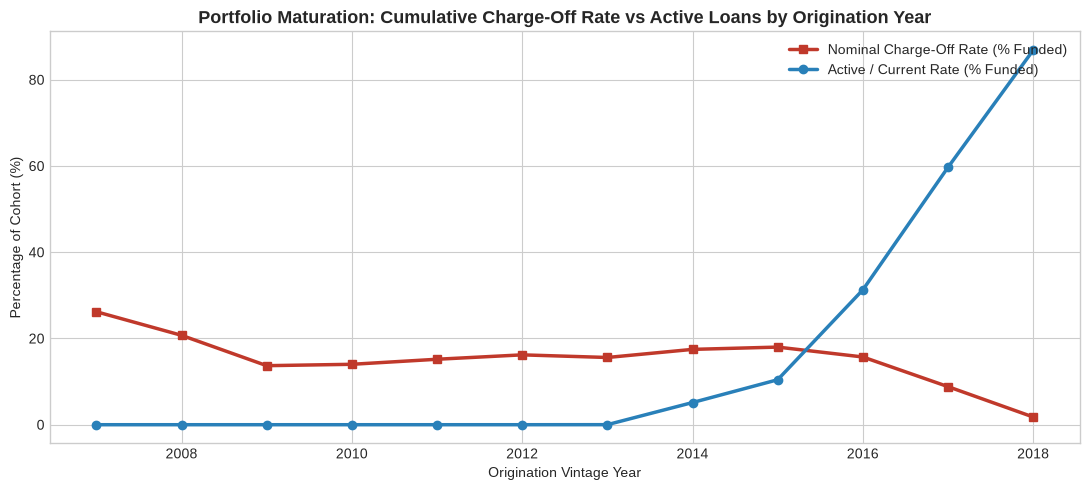

,orig_year,total_funded_loans,charged_off_count,cumulative_charge_off_rate,current_rate
0,2007,603,158,0.2620,0.0000
1,2008,2393,496,0.2073,0.0000
2,2009,5281,723,0.1369,0.0000
3,2010,12537,1757,0.1401,0.0000
4,2011,21721,3297,0.1518,0.0000
5,2012,53367,8644,0.1620,0.0000
6,2013,134814,21024,0.1559,0.0001
7,2014,235629,41162,0.1747,0.0514
8,2015,421095,75804,0.1800,0.1043
9,2016,434407,68252,0.1571,0.3127


In [5]:
df_cohort = pd.read_csv('data/marts/mart_cohort_vintage.csv')

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df_cohort['orig_year'], df_cohort['cumulative_charge_off_rate'] * 100, marker='s', color='#c0392b', linewidth=2.5, label='Nominal Charge-Off Rate (% Funded)')
ax.plot(df_cohort['orig_year'], df_cohort['current_rate'] * 100, marker='o', color='#2980b9', linewidth=2.5, label='Active / Current Rate (% Funded)')
ax.set_title('Portfolio Maturation: Cumulative Charge-Off Rate vs Active Loans by Origination Year', fontsize=13, fontweight='bold')
ax.set_xlabel('Origination Vintage Year')
ax.set_ylabel('Percentage of Cohort (%)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

df_cohort[['orig_year', 'total_funded_loans', 'charged_off_count', 'cumulative_charge_off_rate', 'current_rate']]


## 5. Segment Value Matrix (Approval vs Realized Credit Risk)
Identifying Quadrant II (Growth Opportunities: High Rejection but Low Default) vs Quadrant IV (Danger Zones: High Approval with High Default).


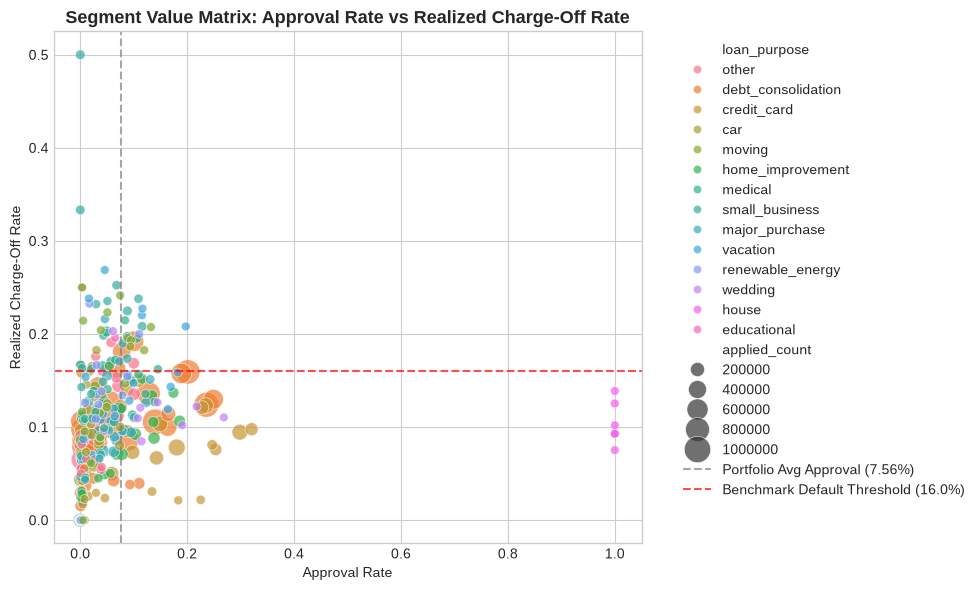

In [6]:
df_quad = pd.read_csv('data/marts/mart_segment_risk_return.csv')

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_quad,
    x='approval_rate',
    y='charge_off_rate',
    size='applied_count',
    hue='loan_purpose',
    sizes=(40, 400),
    alpha=0.7
)
plt.axvline(0.0756, color='grey', linestyle='--', alpha=0.7, label='Portfolio Avg Approval (7.56%)')
plt.axhline(0.1600, color='red', linestyle='--', alpha=0.7, label='Benchmark Default Threshold (16.0%)')
plt.title('Segment Value Matrix: Approval Rate vs Realized Charge-Off Rate', fontsize=13, fontweight='bold')
plt.xlabel('Approval Rate')
plt.ylabel('Realized Charge-Off Rate')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 6. Underwriting Policy Scenario Simulations
Evaluating proposed interventions with sensitivity ranges (Pessimistic, Base Case, Optimistic).


In [7]:
df_scenarios = run_all_scenarios()
df_scenarios[['scenario', 'sensitivity_tier', 'incremental_funded_loans', 'incremental_funded_volume_usd', 'expected_charge_off_rate', 'expected_credit_losses_usd']]


,scenario,sensitivity_tier,incremental_funded_loans,incremental_funded_volume_usd,expected_charge_off_rate,expected_credit_losses_usd
0,Scenario 1: Near-Prime Tiered DTI Expansion,Pessimistic (+35% Risk Surge),92350,1.251341e+09,0.189,2.365034e+08
1,Scenario 1: Near-Prime Tiered DTI Expansion,Base Case (Cohort Parity),92350,1.251341e+09,0.140,1.751877e+08
2,Scenario 1: Near-Prime Tiered DTI Expansion,Optimistic (-15% Risk Reduction),92350,1.251341e+09,0.119,1.489095e+08
3,Scenario 2: Small Business Risk Tightening,Pessimistic (Excess Churn / Lost Margin),-1436,-4.747285e+07,0.245,1.163085e+07
4,Scenario 2: Small Business Risk Tightening,Base Case (Targeted Risk Pruning),-1197,-3.957173e+07,0.215,8.507922e+06
5,Scenario 2: Small Business Risk Tightening,Optimistic (Capital Re-allocation),-957,-3.163755e+07,0.180,5.694759e+06


## 7. Executive Recommendations for NBFC Credit Committee
1. **Execute Near-Prime DTI Expansion:** Pilot an automated tiered approval program for applicants with DTI 20–28% and employment tenure >= 5 years. This unlocks an estimated **\$1.25B in incremental origination volume** with expected credit losses safely bounded between 11.9% and 18.9%.
2. **Institute Small Business Ticket Capping:** Restrict unsecured small business loans exceeding \$25,000, preserving up to **\$11.6M in direct write-offs** with minimal impact on core consumer NIM.
